# Abrupt p–n junction under the depletion approximation

Prerequisite: [Nondegenerate abrupt p–n junction](../../../docs/lecture-notes/solidstate/semiconductors/abrupt-pn-junction/index.md).

## Learning objectives

- compute intrinsic density, built-in potential, and depletion widths;
- inspect charge, electrostatic, band, and carrier profiles;
- verify charge-balance and mass-action identities; and
- identify the limits of the abrupt depletion approximation.

Run the cells from top to bottom.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from projectkoios.physkit.solidstate.semiconductors.junction import (
    AbruptDopingProfile,
    AbruptPNJunction,
    SemiconductorMaterial,
)

In [2]:
silicon = SemiconductorMaterial(
    band_gap=1.12,
    electron_affinity=4.05,
    relative_permittivity=11.7,
    conduction_density_of_states=2.8e25,
    valence_density_of_states=1.04e25,
    electron_mobility=1350.0e-4,
    hole_mobility=480.0e-4,
    temperature=300.0,
)
doping = AbruptDopingProfile(
    acceptor_density=1.0e23,
    donor_density=1.0e22,
)
junction = AbruptPNJunction(material=silicon, doping=doping)

In [3]:
built_in_potential = junction.built_in_potential()
widths = junction.depletion_widths()

np.testing.assert_allclose(
    doping.acceptor_density * widths.p_side,
    doping.donor_density * widths.n_side,
)
print(f"intrinsic carrier density: {silicon.intrinsic_carrier_density:.3e} m^-3")
print(f"built-in potential: {built_in_potential:.3f} V")
print(f"total depletion width: {widths.total * 1.0e6:.3f} µm")
print(f"p-side width: {widths.p_side * 1.0e6:.3f} µm")
print(f"n-side width: {widths.n_side * 1.0e6:.3f} µm")

intrinsic carrier density: 6.676e+15 m^-3
built-in potential: 0.795 V
total depletion width: 0.336 µm
p-side width: 0.031 µm
n-side width: 0.306 µm


In [4]:
equilibrium = junction.solve_equilibrium(point_count=301)
x_micrometer = equilibrium.position * 1.0e6

np.testing.assert_allclose(equilibrium.electrostatic_potential[0], 0.0, atol=1.0e-12)
np.testing.assert_allclose(equilibrium.electrostatic_potential[-1], built_in_potential)
np.testing.assert_allclose(
    equilibrium.carriers.electron * equilibrium.carriers.hole,
    silicon.intrinsic_carrier_density**2,
    rtol=2.0e-14,
)

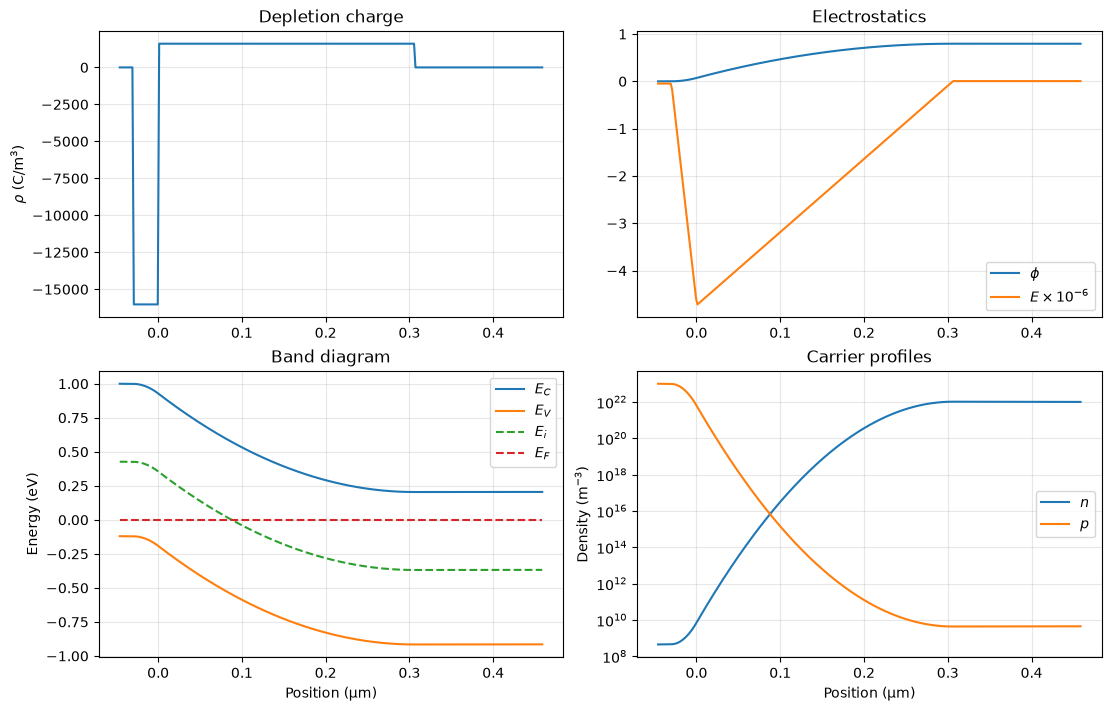

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)

axes[0, 0].plot(x_micrometer, equilibrium.charge_density)
axes[0, 0].set(title="Depletion charge", ylabel=r"$\rho$ (C/m$^3$)")
axes[0, 1].plot(x_micrometer, equilibrium.electrostatic_potential, label=r"$\phi$")
axes[0, 1].plot(x_micrometer, equilibrium.electric_field * 1.0e-6, label=r"$E \times 10^{-6}$")
axes[0, 1].set(title="Electrostatics")
axes[0, 1].legend()

axes[1, 0].plot(x_micrometer, equilibrium.bands.conduction, label=r"$E_C$")
axes[1, 0].plot(x_micrometer, equilibrium.bands.valence, label=r"$E_V$")
axes[1, 0].plot(x_micrometer, equilibrium.bands.intrinsic, "--", label=r"$E_i$")
axes[1, 0].plot(x_micrometer, equilibrium.bands.fermi, "--", label=r"$E_F$")
axes[1, 0].set(title="Band diagram", xlabel="Position (µm)", ylabel="Energy (eV)")
axes[1, 0].legend()

axes[1, 1].semilogy(x_micrometer, equilibrium.carriers.electron, label=r"$n$")
axes[1, 1].semilogy(x_micrometer, equilibrium.carriers.hole, label=r"$p$")
axes[1, 1].set(title="Carrier profiles", xlabel="Position (µm)", ylabel=r"Density (m$^{-3}$)")
axes[1, 1].legend()

for axis in axes.flat:
    axis.grid(True, alpha=0.3)
plt.show()

## Interpretation and questions

The potential boundary values and mass-action identity are numerical checks of this represented model. They do not establish that the depletion approximation predicts a specific fabricated device.

1. How do $W_p$ and $W_n$ change when the donor density is increased?
2. At what forward bias does the depletion-width formula cease to be defined?
3. Why should the current terms not be interpreted as a self-consistent nonequilibrium solution?
4. Which additional equations and boundary conditions would a production drift–diffusion solver require?